RAILPULSE AI — FINAL MODEL EVALUATION
Development trains: 2516
Reserved evaluation trains: 630
Train overlap: 0

Loading data in chunks...
Processed 300,000 rows
Processed 600,000 rows
Processed 900,000 rows

DATA LOADING COMPLETE
Development training shape: (870629, 4)
Reserved evaluation shape: (230814, 4)
Training rows: 870,629
Evaluation rows: 230,814

PERSISTENCE BASELINE
MAE: 9.6001
MSE: 853.1241
RMSE: 29.2083
R2: 0.8618

Training Reduced Delta Learning model...
Training time: 62.73 seconds

REDUCED DELTA LEARNING
MAE: 9.4939
MSE: 846.8970
RMSE: 29.1015
R2: 0.8628

FINAL RESERVED-GROUP MODEL COMPARISON
                 Model  Feature_Count    MAE      MSE    RMSE     R2  Training_Time_Seconds
  Persistence Baseline              1 9.6001 853.1241 29.2083 0.8618                 0.0000
Reduced Delta Learning              4 9.4939 846.8970 29.1015 0.8628                62.7321

Delta Learning MAE improvement: 0.1062 minutes
Percentage improvement: 1.11%

FINAL ERROR ANALYSIS BY ACTUA

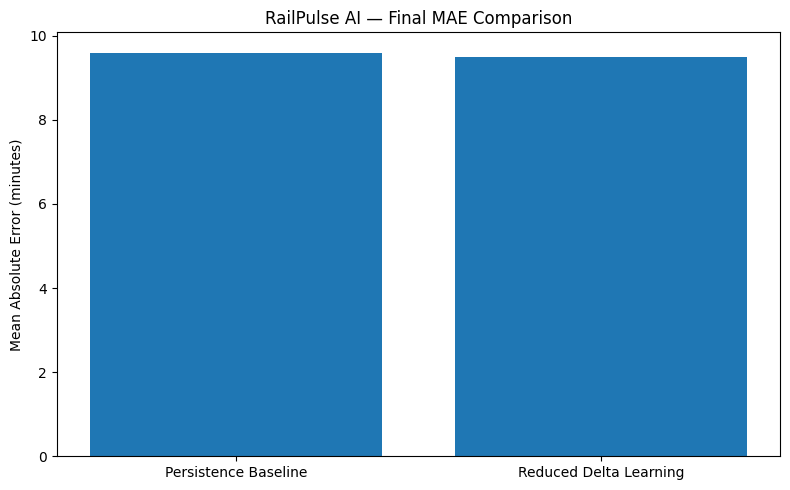


Saved: ../outputs/figures\10_final_mae_comparison.png


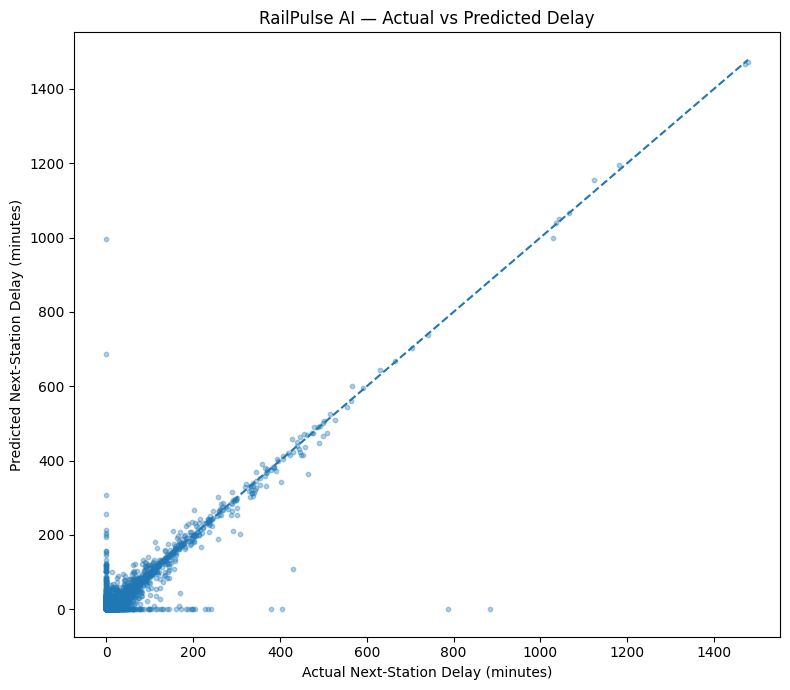


Saved: ../outputs/figures\11_actual_vs_predicted_delay.png

FINAL MODEL EVALUATION COMPLETED
Training trains: 2516
Evaluation trains: 630
Evaluation observations: 230814
Predictors used: ['current_arr_delay', 'distance_to_next', 'current_distance', 'current_sequence']

Important research disclosure:
The reserved evaluation group was examined in earlier exploratory experiments.
It is therefore not described as a completely untouched test set.

All final evaluation outputs saved successfully.


In [2]:

# ============================================================
# RAILPULSE AI — FINAL MODEL EVALUATION
# Reduced Delta Learning vs Persistence Baseline
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_PATH = "../data/processed/railpulse_model_features.csv"

MANIFEST_PATH = (
    "../outputs/tables/three_way_train_split_manifest.csv"
)

OUTPUT_DIR = "../outputs/tables"
FIGURE_DIR = "../outputs/figures"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

CHUNK_SIZE = 100_000
RANDOM_STATE = 42

FEATURES = [
    "current_arr_delay",
    "distance_to_next",
    "current_distance",
    "current_sequence"
]

TARGET = "next_arr_delay"

USE_COLS = ["train"] + FEATURES + [TARGET]

# ------------------------------------------------------------
# 2. LOAD TRAIN-LEVEL SPLIT MANIFEST
# ------------------------------------------------------------

print("=" * 75)
print("RAILPULSE AI — FINAL MODEL EVALUATION")
print("=" * 75)

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={"train": str}
)

development_ids = set(
    manifest.loc[
        manifest["split"].isin(
            ["internal_train", "validation"]
        ),
        "train"
    ]
)

test_ids = set(
    manifest.loc[
        manifest["split"] == "reserved_final_test",
        "train"
    ]
)

assert development_ids.isdisjoint(test_ids)

print("Development trains:", len(development_ids))
print("Reserved evaluation trains:", len(test_ids))
print("Train overlap:", len(development_ids & test_ids))

# ------------------------------------------------------------
# 3. LOAD DEVELOPMENT AND RESERVED TEST DATA
# ------------------------------------------------------------

X_train_parts = []
y_train_parts = []

X_test_parts = []
y_test_parts = []
test_train_parts = []

total_rows = 0

print("\nLoading data in chunks...")

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=USE_COLS,
    dtype={"train": str},
    chunksize=CHUNK_SIZE
):

    total_rows += len(chunk)

    train_mask = chunk["train"].isin(
        development_ids
    ).to_numpy()

    test_mask = chunk["train"].isin(
        test_ids
    ).to_numpy()

    X = chunk[FEATURES].to_numpy(
        dtype=np.float32
    )

    y = chunk[TARGET].to_numpy(
        dtype=np.float32
    )

    if train_mask.any():
        X_train_parts.append(X[train_mask])
        y_train_parts.append(y[train_mask])

    if test_mask.any():
        X_test_parts.append(X[test_mask])
        y_test_parts.append(y[test_mask])

        test_train_parts.append(
            chunk.loc[test_mask, "train"].to_numpy()
        )

    if total_rows % 300_000 < CHUNK_SIZE:
        print(f"Processed {total_rows:,} rows")

X_train = np.concatenate(X_train_parts)
y_train = np.concatenate(y_train_parts)

X_test = np.concatenate(X_test_parts)
y_test = np.concatenate(y_test_parts)

test_train_ids = np.concatenate(test_train_parts)

del X_train_parts, y_train_parts
del X_test_parts, y_test_parts, test_train_parts
gc.collect()

print("\nDATA LOADING COMPLETE")
print("Development training shape:", X_train.shape)
print("Reserved evaluation shape:", X_test.shape)
print("Training rows:", f"{len(y_train):,}")
print("Evaluation rows:", f"{len(y_test):,}")

assert X_train.shape[1] == len(FEATURES)
assert X_test.shape[1] == len(FEATURES)
assert len(X_test) == len(y_test) == len(test_train_ids)

# ------------------------------------------------------------
# 4. DEFINE METRIC FUNCTION
# ------------------------------------------------------------

def evaluate_model(actual, predicted):

    mse = mean_squared_error(
        actual,
        predicted
    )

    return {
        "MAE": mean_absolute_error(
            actual,
            predicted
        ),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(
            actual,
            predicted
        )
    }

# ------------------------------------------------------------
# 5. PERSISTENCE BASELINE
# ------------------------------------------------------------

delay_index = FEATURES.index(
    "current_arr_delay"
)

current_test_delay = X_test[:, delay_index]

persistence_predictions = current_test_delay.copy()

persistence_metrics = evaluate_model(
    y_test,
    persistence_predictions
)

print("\nPERSISTENCE BASELINE")
for metric, value in persistence_metrics.items():
    print(f"{metric}: {value:.4f}")

# ------------------------------------------------------------
# 6. TRAIN REDUCED DELTA LEARNING MODEL
# ------------------------------------------------------------

current_train_delay = X_train[:, delay_index]

delta_target = (
    y_train - current_train_delay
).astype(np.float32)

delta_model = HistGradientBoostingRegressor(
    loss="absolute_error",
    learning_rate=0.06,
    max_iter=100,
    max_leaf_nodes=31,
    min_samples_leaf=40,
    l2_regularization=2.0,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=12,
    random_state=RANDOM_STATE
)

print("\nTraining Reduced Delta Learning model...")

start = time.time()

delta_model.fit(
    X_train,
    delta_target
)

training_time = time.time() - start

print(
    f"Training time: {training_time:.2f} seconds"
)

# ------------------------------------------------------------
# 7. PREDICT NEXT-STATION DELAY
# ------------------------------------------------------------

predicted_change = delta_model.predict(
    X_test
)

delta_predictions = np.maximum(
    current_test_delay + predicted_change,
    0
)

delta_metrics = evaluate_model(
    y_test,
    delta_predictions
)

print("\nREDUCED DELTA LEARNING")
for metric, value in delta_metrics.items():
    print(f"{metric}: {value:.4f}")

# ------------------------------------------------------------
# 8. FINAL MODEL COMPARISON
# ------------------------------------------------------------

final_results = pd.DataFrame([
    {
        "Model": "Persistence Baseline",
        "Feature_Count": 1,
        **persistence_metrics,
        "Training_Time_Seconds": 0
    },
    {
        "Model": "Reduced Delta Learning",
        "Feature_Count": len(FEATURES),
        **delta_metrics,
        "Training_Time_Seconds": training_time
    }
])

print("\n" + "=" * 85)
print("FINAL RESERVED-GROUP MODEL COMPARISON")
print("=" * 85)

print(
    final_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Calculate percentage MAE improvement
mae_improvement = (
    persistence_metrics["MAE"] -
    delta_metrics["MAE"]
)

improvement_percent = (
    mae_improvement /
    persistence_metrics["MAE"]
) * 100

print(
    f"\nDelta Learning MAE improvement: "
    f"{mae_improvement:.4f} minutes"
)

print(
    f"Percentage improvement: "
    f"{improvement_percent:.2f}%"
)

# ------------------------------------------------------------
# 9. ERROR ANALYSIS
# ------------------------------------------------------------

error_df = pd.DataFrame({
    "train": test_train_ids,
    "actual_delay": y_test,
    "persistence_prediction": persistence_predictions,
    "delta_prediction": delta_predictions
})

error_df["persistence_abs_error"] = (
    error_df["actual_delay"] -
    error_df["persistence_prediction"]
).abs()

error_df["delta_abs_error"] = (
    error_df["actual_delay"] -
    error_df["delta_prediction"]
).abs()

bins = [-0.001, 0, 15, 60, 180, 720, np.inf]

labels = [
    "On time (0)",
    "1-15 min",
    "16-60 min",
    "61-180 min",
    "181-720 min",
    ">720 min"
]

error_df["delay_category"] = pd.cut(
    error_df["actual_delay"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

category_results = error_df.groupby(
    "delay_category",
    observed=False
).agg(
    observations=("actual_delay", "size"),
    persistence_MAE=("persistence_abs_error", "mean"),
    delta_MAE=("delta_abs_error", "mean")
).reset_index()

category_results["MAE_improvement"] = (
    category_results["persistence_MAE"] -
    category_results["delta_MAE"]
)

print("\n" + "=" * 85)
print("FINAL ERROR ANALYSIS BY ACTUAL DELAY CATEGORY")
print("=" * 85)

print(
    category_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. PREDICTION RESIDUAL SUMMARY
# ------------------------------------------------------------

error_df["delta_residual"] = (
    error_df["actual_delay"] -
    error_df["delta_prediction"]
)

print("\nDELTA MODEL RESIDUAL SUMMARY")
print(
    error_df["delta_residual"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(3)
)

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

final_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_reserved_group_model_comparison.csv"
    ),
    index=False
)

category_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_reserved_group_category_analysis.csv"
    ),
    index=False
)

error_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_reserved_group_predictions.csv"
    ),
    index=False
)

print("\nSaved final evaluation tables.")

# ------------------------------------------------------------
# 12. VISUALIZATION — MAE COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    final_results["Model"],
    final_results["MAE"]
)

plt.ylabel("Mean Absolute Error (minutes)")
plt.title("RailPulse AI — Final MAE Comparison")

plt.tight_layout()

mae_figure = os.path.join(
    FIGURE_DIR,
    "10_final_mae_comparison.png"
)

plt.savefig(
    mae_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", mae_figure)

# ------------------------------------------------------------
# 13. VISUALIZATION — PREDICTED VS ACTUAL
# ------------------------------------------------------------

plot_rng = np.random.default_rng(RANDOM_STATE)

plot_size = min(
    5000,
    len(y_test)
)

plot_indices = plot_rng.choice(
    len(y_test),
    size=plot_size,
    replace=False
)

plt.figure(figsize=(8, 7))

plt.scatter(
    y_test[plot_indices],
    delta_predictions[plot_indices],
    s=10,
    alpha=0.35
)

maximum_value = max(
    float(y_test[plot_indices].max()),
    float(delta_predictions[plot_indices].max())
)

plt.plot(
    [0, maximum_value],
    [0, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Next-Station Delay (minutes)")
plt.ylabel("Predicted Next-Station Delay (minutes)")

plt.title(
    "RailPulse AI — Actual vs Predicted Delay"
)

plt.tight_layout()

prediction_figure = os.path.join(
    FIGURE_DIR,
    "11_actual_vs_predicted_delay.png"
)

plt.savefig(
    prediction_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", prediction_figure)

# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL MODEL EVALUATION COMPLETED")
print("=" * 75)

print("Training trains:", len(development_ids))
print("Evaluation trains:", len(test_ids))
print("Evaluation observations:", len(y_test))
print("Predictors used:", FEATURES)

print("\nImportant research disclosure:")
print(
    "The reserved evaluation group was examined in earlier "
    "exploratory experiments."
)
print(
    "It is therefore not described as a completely untouched "
    "test set."
)

# ------------------------------------------------------------
# 15. RELEASE MEMORY
# ------------------------------------------------------------

del delta_model
del delta_target
del predicted_change
del error_df
gc.collect()

print("\nAll final evaluation outputs saved successfully.")


In [3]:

# ============================================================
# RAILPULSE AI — EXTREME RESIDUAL INVESTIGATION
# ============================================================

import os
import gc
import numpy as np
import pandas as pd

DATA_PATH = "../data/processed/railpulse_model_features.csv"
OUTPUT_DIR = "../outputs/tables"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD MATCHING TEST-OBSERVATION METADATA
# ------------------------------------------------------------

metadata_parts = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[
        "train",
        "date",
        "current_station",
        "next_station"
    ],
    dtype={"train": str},
    chunksize=100_000
):

    mask = chunk["train"].isin(test_ids)

    if mask.any():
        metadata_parts.append(
            chunk.loc[mask].copy()
        )

metadata = pd.concat(
    metadata_parts,
    ignore_index=True
)

del metadata_parts
gc.collect()

# Confirm metadata ordering matches the evaluation arrays
assert len(metadata) == len(y_test)
assert np.array_equal(
    metadata["train"].to_numpy(),
    test_train_ids
)

# ------------------------------------------------------------
# 2. BUILD RESIDUAL AUDIT TABLE
# ------------------------------------------------------------

residual_audit = metadata.copy()

residual_audit["actual_delay"] = y_test
residual_audit["persistence_prediction"] = (
    persistence_predictions
)
residual_audit["delta_prediction"] = (
    delta_predictions
)

residual_audit["residual"] = (
    residual_audit["actual_delay"] -
    residual_audit["delta_prediction"]
)

residual_audit["absolute_error"] = (
    residual_audit["residual"].abs()
)

# ------------------------------------------------------------
# 3. SUMMARIZE EXTREME ERRORS
# ------------------------------------------------------------

print("=" * 75)
print("RAILPULSE AI — EXTREME RESIDUAL AUDIT")
print("=" * 75)

print("Evaluation observations:", len(residual_audit))

print("\nERROR THRESHOLD COUNTS")

for threshold in [30, 60, 180, 720, 1440]:
    count = (
        residual_audit["absolute_error"] > threshold
    ).sum()

    percentage = count / len(residual_audit) * 100

    print(
        f"Absolute error > {threshold:4} min: "
        f"{count:7,} ({percentage:.3f}%)"
    )

# ------------------------------------------------------------
# 4. EXAMINE LARGEST ERRORS
# ------------------------------------------------------------

largest_errors = residual_audit.sort_values(
    "absolute_error",
    ascending=False
).head(30)

display_columns = [
    "train",
    "date",
    "current_station",
    "next_station",
    "actual_delay",
    "persistence_prediction",
    "delta_prediction",
    "residual",
    "absolute_error"
]

print("\nTOP 30 LARGEST PREDICTION ERRORS")

print(
    largest_errors[display_columns].to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 5. CHECK ERRORS NEAR 24-HOUR DIFFERENCES
# ------------------------------------------------------------

near_1440 = residual_audit[
    (residual_audit["absolute_error"] >= 1200) &
    (residual_audit["absolute_error"] <= 1500)
].copy()

print("\nERRORS BETWEEN 1200 AND 1500 MINUTES")
print("Count:", len(near_1440))

if len(near_1440) > 0:
    print(
        near_1440[display_columns]
        .head(30)
        .to_string(index=False)
    )

# ------------------------------------------------------------
# 6. SAVE AUDIT TABLES
# ------------------------------------------------------------

largest_errors[display_columns].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_top_30_prediction_errors.csv"
    ),
    index=False
)

near_1440[display_columns].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_residuals_near_1440_minutes.csv"
    ),
    index=False
)

print("\nResidual audit files saved.")

print("\nEXTREME RESIDUAL INVESTIGATION COMPLETED.")


RAILPULSE AI — EXTREME RESIDUAL AUDIT
Evaluation observations: 230814

ERROR THRESHOLD COUNTS
Absolute error >   30 min:  14,603 (6.327%)
Absolute error >   60 min:   4,766 (2.065%)
Absolute error >  180 min:     857 (0.371%)
Absolute error >  720 min:      44 (0.019%)
Absolute error > 1440 min:       1 (0.000%)

TOP 30 LARGEST PREDICTION ERRORS
train       date current_station next_station  actual_delay  persistence_prediction  delta_prediction     residual  absolute_error
20806 2024-09-02             NGP           CD           0.0                  1444.0       1446.186431 -1446.186431     1446.186431
12687 2024-09-04             BPL         VGLJ        1439.0                     0.0          0.000000  1439.000000     1439.000000
12785 2024-09-22             DMM          PKD           0.0                  1431.0       1432.360607 -1432.360607     1432.360607
12785 2024-09-22            DHNE           GY        1435.0                     6.0          6.123543  1428.876457     1428.8764

In [4]:

# ============================================================
# RAILPULSE AI — ORIGINAL TIMESTAMP VERIFICATION
# ============================================================

import os
import pandas as pd

PAIR_PATH = "../data/processed/railpulse_next_station_pairs.csv"

# Use the top-error records already created by the previous cell
top_cases = largest_errors[
    ["train", "date", "current_station", "next_station"]
].copy()

# Normalize join keys
for col in ["train", "date", "current_station", "next_station"]:
    top_cases[col] = top_cases[col].astype(str).str.strip()

matched_parts = []
total_scanned = 0

print("Searching original paired dataset...")

for chunk in pd.read_csv(
    PAIR_PATH,
    dtype=str,
    chunksize=100_000
):

    total_scanned += len(chunk)

    required = [
        "train", "date", "current_station", "next_station"
    ]

    missing_columns = [
        c for c in required if c not in chunk.columns
    ]

    if missing_columns:
        print("Missing expected join columns:", missing_columns)
        print("Available columns:", chunk.columns.tolist())
        raise ValueError(
            "Paired dataset schema differs from expected columns."
        )

    for col in required:
        chunk[col] = chunk[col].str.strip()

    matched = chunk.merge(
        top_cases.drop_duplicates(),
        on=required,
        how="inner"
    )

    if not matched.empty:
        matched_parts.append(matched)

    if total_scanned % 300_000 == 0:
        print(f"Scanned {total_scanned:,} rows")

if matched_parts:
    original_cases = pd.concat(
        matched_parts,
        ignore_index=True
    )

    print("\nMATCHED ORIGINAL RECORDS")
    print("Records found:", len(original_cases))

    print("\nAvailable original fields:")
    print(original_cases.columns.tolist())

    # Display every field for these records
    with pd.option_context(
        "display.max_columns", None,
        "display.max_rows", 40,
        "display.width", 250
    ):
        display(original_cases.head(40))

    original_cases.to_csv(
        "../outputs/tables/extreme_errors_original_timestamp_audit.csv",
        index=False
    )

    print(
        "\nSaved: extreme_errors_original_timestamp_audit.csv"
    )

else:
    print("No matching records found.")
    print("Check the join-key formatting and dataset schema.")

print("\nOriginal timestamp verification completed.")


Searching original paired dataset...
Scanned 300,000 rows
Scanned 600,000 rows
Scanned 900,000 rows

MATCHED ORIGINAL RECORDS
Records found: 30

Available original fields:
['train', 'date', 'current_station', 'next_station', 'current_arr_delay', 'next_arr_delay', 'current_scheduled_arrival', 'current_actual_arrival', 'current_scheduled_departure', 'current_actual_departure', 'current_sequence', 'current_distance', 'next_distance', 'distance_to_next']


,train,date,current_station,next_station,current_arr_delay,next_arr_delay,current_scheduled_arrival,current_actual_arrival,current_scheduled_departure,current_actual_departure,current_sequence,current_distance,next_distance,distance_to_next
0,16031,2024-09-01,SEGM,NGP,0.0,1271.0,12:23 AM,12:23 AM,12:25 AM,12:25 AM,30,1039,1115.0,76.0
1,12655,2024-09-02,JL,BSL,875.0,0.0,06:28 AM,09:03 PM,06:30 AM,09:05 PM,14,538,562.0,24.0
2,20806,2024-09-02,NGP,CD,1444.0,0.0,10:25 AM,10:29 AM,10:30 AM,10:34 AM,6,1088,1282.0,194.0
3,20497,2024-09-03,CD,NGP,0.0,915.0,11:30 PM,11:30 PM,11:32 PM,11:32 PM,15,1500,1695.0,195.0
4,12687,2024-09-04,BPL,VGLJ,0.0,1439.0,09:30 AM,09:30 AM,09:40 AM,09:40 AM,20,2082,2372.0,290.0
5,12615,2024-09-05,SEGM,NGP,0.0,1040.0,10:03 AM,10:03 AM,10:05 AM,10:05 AM,16,1022,1098.0,76.0
6,12615,2024-09-05,NGP,NRKR,1040.0,0.0,11:25 AM,04:45 AM,11:30 AM,04:50 AM,17,1098,1182.0,84.0
7,12615,2024-09-05,NRKR,PAR,0.0,1056.0,12:33 PM,12:33 PM,12:34 PM,12:34 PM,18,1182,1200.0,18.0
8,12615,2024-09-05,BPL,SCI,995.0,0.0,06:40 PM,11:15 AM,06:45 PM,11:20 AM,26,1485,1529.0,44.0
9,12615,2024-09-05,SCI,BHS,0.0,1002.0,07:10 PM,07:10 PM,07:12 PM,07:12 PM,27,1529,1538.0,9.0



Saved: extreme_errors_original_timestamp_audit.csv

Original timestamp verification completed.


In [5]:

# ============================================================
# RAILPULSE AI — ORIGINAL JSON STRUCTURE INSPECTION
# Memory-safe inspection; does not load the full dataset
# ============================================================

from pathlib import Path
import json

JSON_PATH = Path(
    "../data/interim/RSTGCN/"
    "Indian-Railway-Network-and-Delays/"
    "train_delays_Sep2024.json"
)

print("=" * 75)
print("RAILPULSE AI — ORIGINAL DELAY JSON INSPECTION")
print("=" * 75)

if not JSON_PATH.exists():
    raise FileNotFoundError(
        f"Could not find file: {JSON_PATH.resolve()}"
    )

print("File:", JSON_PATH.resolve())
print("Size:", round(JSON_PATH.stat().st_size / (1024 * 1024), 2), "MB")

# Read only a small beginning section
with open(JSON_PATH, "rb") as f:
    beginning = f.read(5000)

print("\nFIRST 5000 BYTES")
print("-" * 75)

print(
    beginning.decode(
        "utf-8",
        errors="replace"
    )
)

# Inspect the first and last non-whitespace characters
with open(JSON_PATH, "rb") as f:
    f.seek(0)
    first_bytes = f.read(100)

    f.seek(max(0, JSON_PATH.stat().st_size - 500))
    last_bytes = f.read(500)

print("\nFILE BEGINNING:")
print(first_bytes.decode("utf-8", errors="replace"))

print("\nFILE ENDING:")
print(last_bytes.decode("utf-8", errors="replace"))

print("\nINSPECTION COMPLETED")
print("No records were modified.")


RAILPULSE AI — ORIGINAL DELAY JSON INSPECTION
File: C:\Users\Login\Documents\RailPulse_AI\data\interim\RSTGCN\Indian-Railway-Network-and-Delays\train_delays_Sep2024.json
Size: 89.78 MB

FIRST 5000 BYTES
---------------------------------------------------------------------------
{"12303": {"01-09-2024": {}, "02-09-2024": {"HWH": ["08:00 AM", "08:01 AM", "00M", "08:00 AM", "08:01 AM", "00M"], "BWN": ["09:05 AM", "09:20 AM", "15M", "09:08 AM", "09:23 AM", "15M"], "DGR": ["09:57 AM", "10:00 AM", "03M", "09:59 AM", "10:02 AM", "03M"], "ASN": ["10:32 AM", "10:34 AM", "02M", "10:37 AM", "10:39 AM", "02M"], "CRJ": ["11:00 AM", "11:04 AM", "04M", "11:02 AM", "11:06 AM", "04M"], "JMT": ["11:15 AM", "11:17 AM", "02M", "11:17 AM", "11:19 AM", "02M"], "MDP": ["11:44 AM", "11:46 AM", "02M", "11:46 AM", "11:48 AM", "02M"], "JSME": ["12:11 PM", "12:11 PM", "00M", "12:15 PM", "12:15 PM", "00M"], "JAJ": ["01:12 PM", "01:12 PM", "00M", "01:17 PM", "01:17 PM", "00M"], "JMU": ["01:33 PM", "01:37 PM", "04M"

In [6]:
%pip install ijson

Note: you may need to restart the kernel to use updated packages.


In [7]:

# ============================================================
# RAILPULSE AI — TARGETED ORIGINAL TIMESTAMP VERIFICATION
# Reads only the required trains from the nested JSON
# ============================================================

import os
import re
import gc
import ijson
import pandas as pd
import numpy as np

JSON_PATH = (
    "../data/interim/RSTGCN/"
    "Indian-Railway-Network-and-Delays/"
    "train_delays_Sep2024.json"
)

OUTPUT_DIR = "../outputs/tables"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. PREPARE THE 30 EXTREME CASES
# ------------------------------------------------------------

cases = largest_errors[
    ["train", "date", "current_station", "next_station",
     "actual_delay", "delta_prediction", "residual",
     "absolute_error"]
].copy()

cases["train"] = cases["train"].astype(str).str.strip()
cases["current_station"] = (
    cases["current_station"].astype(str).str.strip()
)
cases["next_station"] = (
    cases["next_station"].astype(str).str.strip()
)

cases["date"] = pd.to_datetime(
    cases["date"]
).dt.strftime("%d-%m-%Y")

target_trains = set(cases["train"].unique())

# Only inspect dates and stations needed for these cases
required = {}

for _, row in cases.iterrows():

    key = (row["train"], row["date"])

    if key not in required:
        required[key] = set()

    required[key].add(row["current_station"])
    required[key].add(row["next_station"])

print("=" * 75)
print("RAILPULSE AI — TARGETED JSON AUDIT")
print("=" * 75)

print("Extreme cases:", len(cases))
print("Unique trains:", len(target_trains))
print("Train-date combinations:", len(required))

# ------------------------------------------------------------
# 2. PARSE ONLY REQUIRED TRAINS
# ------------------------------------------------------------

original_lookup = {}

with open(JSON_PATH, "rb") as f:

    for train_number, train_data in ijson.kvitems(f, ""):

        train_number = str(train_number)

        if train_number not in target_trains:
            continue

        for date_key, station_data in train_data.items():

            lookup_key = (train_number, date_key)

            if lookup_key not in required:
                continue

            required_stations = required[lookup_key]

            for station_code in required_stations:

                values = station_data.get(station_code)

                if not isinstance(values, list):
                    continue

                original_lookup[
                    (train_number, date_key, station_code)
                ] = {
                    "scheduled_arrival": (
                        values[0] if len(values) > 0 else None
                    ),
                    "actual_arrival": (
                        values[1] if len(values) > 1 else None
                    ),
                    "reported_arrival_delay": (
                        values[2] if len(values) > 2 else None
                    ),
                    "scheduled_departure": (
                        values[3] if len(values) > 3 else None
                    ),
                    "actual_departure": (
                        values[4] if len(values) > 4 else None
                    ),
                    "reported_departure_delay": (
                        values[5] if len(values) > 5 else None
                    )
                }

print("\nOriginal station records retrieved:",
      len(original_lookup))

# ------------------------------------------------------------
# 3. HELPER — CONVERT CLOCK TIME TO MINUTES
# ------------------------------------------------------------

def clock_to_minutes(value):

    if not value:
        return np.nan

    try:
        parsed = pd.to_datetime(
            value,
            format="%I:%M %p"
        )

        return (
            parsed.hour * 60 +
            parsed.minute
        )

    except Exception:
        return np.nan

# ------------------------------------------------------------
# 4. HELPER — PARSE REPORTED DELAY TEXT
# ------------------------------------------------------------

def delay_text_to_minutes(value):

    if value is None:
        return np.nan

    text = str(value).strip().upper()

    if text in ["", "NAN", "NONE"]:
        return np.nan

    hours = re.search(r"(\d+)\s*H", text)
    minutes = re.search(r"(\d+)\s*M", text)

    h = int(hours.group(1)) if hours else 0
    m = int(minutes.group(1)) if minutes else 0

    return h * 60 + m

# ------------------------------------------------------------
# 5. BUILD CURRENT AND NEXT STATION AUDIT
# ------------------------------------------------------------

audit_rows = []

for _, case in cases.iterrows():

    train = case["train"]
    date_key = case["date"]

    for position, station in [
        ("current", case["current_station"]),
        ("next", case["next_station"])
    ]:

        key = (train, date_key, station)

        record = original_lookup.get(key)

        if record is None:
            record = {
                "scheduled_arrival": None,
                "actual_arrival": None,
                "reported_arrival_delay": None,
                "scheduled_departure": None,
                "actual_departure": None,
                "reported_departure_delay": None
            }

        scheduled = clock_to_minutes(
            record["scheduled_arrival"]
        )

        actual = clock_to_minutes(
            record["actual_arrival"]
        )

        reported = delay_text_to_minutes(
            record["reported_arrival_delay"]
        )

        clock_difference = np.nan

        if not np.isnan(scheduled) and not np.isnan(actual):

            clock_difference = (
                actual - scheduled
            ) % 1440

        audit_rows.append({
            "train": train,
            "date": date_key,
            "position": position,
            "station": station,
            **record,
            "clock_difference_mod_1440": clock_difference,
            "reported_arrival_delay_minutes": reported,
            "difference_reported_vs_clock": (
                reported - clock_difference
                if not np.isnan(reported)
                and not np.isnan(clock_difference)
                else np.nan
            )
        })

timestamp_audit = pd.DataFrame(audit_rows)

# ------------------------------------------------------------
# 6. MERGE CURRENT AND NEXT STATION INFORMATION
# ------------------------------------------------------------

current_records = timestamp_audit[
    timestamp_audit["position"] == "current"
].copy()

next_records = timestamp_audit[
    timestamp_audit["position"] == "next"
].copy()

current_records = current_records.add_prefix("current_")
next_records = next_records.add_prefix("next_")

comparison = pd.concat(
    [
        current_records.reset_index(drop=True),
        next_records.reset_index(drop=True)
    ],
    axis=1
)

# Attach model evaluation values
comparison["model_actual_next_delay"] = (
    cases["actual_delay"].to_numpy()
)

comparison["model_delta_prediction"] = (
    cases["delta_prediction"].to_numpy()
)

comparison["model_absolute_error"] = (
    cases["absolute_error"].to_numpy()
)

# ------------------------------------------------------------
# 7. PRINT AUDIT RESULTS
# ------------------------------------------------------------

display_columns = [
    "current_train",
    "current_date",
    "current_station",
    "current_scheduled_arrival",
    "current_actual_arrival",
    "current_reported_arrival_delay",
    "current_difference_reported_vs_clock",
    "next_station",
    "next_scheduled_arrival",
    "next_actual_arrival",
    "next_reported_arrival_delay",
    "next_difference_reported_vs_clock",
    "model_actual_next_delay",
    "model_delta_prediction",
    "model_absolute_error"
]

print("\n" + "=" * 100)
print("ORIGINAL CURRENT-AND-NEXT STATION TIMESTAMP COMPARISON")
print("=" * 100)

with pd.option_context(
    "display.max_columns", None,
    "display.max_rows", 40,
    "display.width", 300
):
    display(comparison[display_columns])

# ------------------------------------------------------------
# 8. CHECK FOR 1440-MINUTE OFFSETS
# ------------------------------------------------------------

print("\nCURRENT STATION CLOCK CONSISTENCY")

print(
    timestamp_audit[
        timestamp_audit["position"] == "current"
    ]["difference_reported_vs_clock"]
    .describe()
)

print("\nNEXT STATION CLOCK CONSISTENCY")

print(
    timestamp_audit[
        timestamp_audit["position"] == "next"
    ]["difference_reported_vs_clock"]
    .describe()
)

# ------------------------------------------------------------
# 9. SAVE AUDIT OUTPUTS
# ------------------------------------------------------------

timestamp_audit.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "extreme_cases_station_timestamp_details.csv"
    ),
    index=False
)

comparison[display_columns].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "extreme_cases_current_next_comparison.csv"
    ),
    index=False
)

print("\nSaved:")
print("extreme_cases_station_timestamp_details.csv")
print("extreme_cases_current_next_comparison.csv")

print("\nTARGETED ORIGINAL TIMESTAMP AUDIT COMPLETED.")

gc.collect()


RAILPULSE AI — TARGETED JSON AUDIT
Extreme cases: 30
Unique trains: 13
Train-date combinations: 17

Original station records retrieved: 51

ORIGINAL CURRENT-AND-NEXT STATION TIMESTAMP COMPARISON


,current_train,current_date,current_station,current_scheduled_arrival,current_actual_arrival,current_reported_arrival_delay,current_difference_reported_vs_clock,next_station,next_scheduled_arrival,next_actual_arrival,next_reported_arrival_delay,next_difference_reported_vs_clock,model_actual_next_delay,model_delta_prediction,model_absolute_error
0,20806,02-09-2024,NGP,10:25 AM,10:29 AM,24H 4M,1440,CD,01:00 PM,01:00 PM,00M,0,0.0,1446.186431,1446.186431
1,12687,04-09-2024,BPL,09:30 AM,09:30 AM,00M,0,VGLJ,02:25 PM,02:24 PM,23H 59M,0,1439.0,0.000000,1439.000000
2,12785,22-09-2024,DMM,02:25 AM,02:16 AM,23H 51M,0,PKD,03:02 AM,03:02 AM,00M,0,0.0,1432.360607,1432.360607
3,12785,22-09-2024,DHNE,11:35 PM,11:41 PM,06M,0,GY,12:44 AM,12:39 AM,23H 55M,0,1435.0,6.123543,1428.876457
4,14204,22-09-2024,LOT,11:29 AM,11:29 AM,00M,0,BSB,11:55 AM,10:45 AM,22H 50M,0,1370.0,0.000000,1370.000000
5,16031,01-09-2024,SEGM,12:23 AM,12:23 AM,00M,0,NGP,01:40 AM,10:51 PM,21H 11M,0,1271.0,0.000000,1271.000000
6,12369,16-09-2024,PNBE,09:10 PM,05:02 PM,19H 52M,0,ARA,10:00 PM,10:00 PM,00M,0,0.0,1193.548677,1193.548677
7,12370,17-09-2024,DDN,09:45 PM,04:49 PM,19H 4M,0,HW,11:35 PM,11:35 PM,00M,0,0.0,1156.051923,1156.051923
8,12370,09-09-2024,PNBE,05:30 PM,11:20 AM,17H 50M,0,BKP,06:13 PM,06:13 PM,00M,0,0.0,1071.336818,1071.336818
9,12615,09-09-2024,SCI,07:10 PM,07:10 PM,00M,0,BHS,07:20 PM,12:58 PM,17H 38M,0,1058.0,0.000000,1058.000000



CURRENT STATION CLOCK CONSISTENCY
count      30.000000
mean       48.000000
std       262.906828
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1440.000000
Name: difference_reported_vs_clock, dtype: float64

NEXT STATION CLOCK CONSISTENCY
count    30.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: difference_reported_vs_clock, dtype: float64

Saved:
extreme_cases_station_timestamp_details.csv
extreme_cases_current_next_comparison.csv

TARGETED ORIGINAL TIMESTAMP AUDIT COMPLETED.


0